1 Derive génétique 

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [25]:
# question 1
def composition_WF(N, t, r0,rng=None):
    if rng is None:
        rng = np.random.default_rng()
    n = np.zeros(t + 1, dtype=int)
    n[0] = round(N * r0)
    for s in range(t):
        n[s + 1] = rng.binomial(N, n[s] / N)
    return n

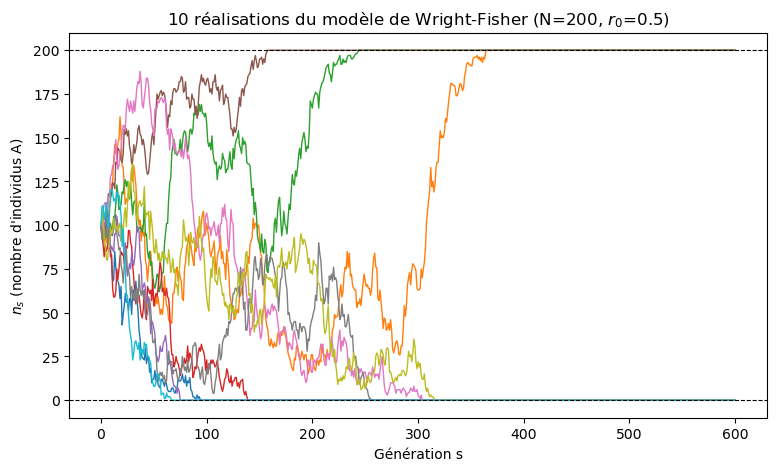

In [26]:
# Tracer les realisations
rng=np.random.default_rng(0)
N, t, r0 = 200, 600, 0.5
nb_real = 10

plt.figure(figsize=(9, 5))
for _ in range(nb_real):
    plt.plot(composition_WF(N, t, r0, rng), lw=1)
plt.axhline(0, color="k", ls="--", lw=0.8)
plt.axhline(N, color="k", ls="--", lw=0.8)
plt.xlabel("Génération s")
plt.ylabel("$n_s$ (nombre d'individus A)")
plt.title(f"{nb_real} réalisations du modèle de Wright-Fisher (N={N}, $r_0$={r0})")
plt.show()

**Interprétation.** On a simulé 10 réalisations du modèle de Wright-Fisher avec N = 200, r₀ = 1/2 et t = 600. Les trajectoires partent toutes de 100 individus, puis évoluent au hasard d'une génération à l'autre : c'est la dérive génétique.

Toutes les trajectoires finissent par atteindre 0 ou 200, puis y restent. Ici, 3 trajectoires atteignent 200 (l'allèle A est fixé) et 7 atteignent 0 (l'allèle A disparaît).

Le temps nécessaire varie beaucoup d'une trajectoire à l'autre : d'environ 65 à 365 générations.

In [27]:
# Question 2 – fonction temps_absorption
def temps_absorption(N, n0, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    n = n0
    T = 0
    while 0 < n < N:
        n = rng.binomial(N, n / N)
        T += 1
    type_fixe = "A" if n == N else "a"
    return T, type_fixe

# Test avec une graine fixée
rng = np.random.default_rng(0)
print(temps_absorption(200, 100, rng))

(94, 'a')


Interprétation. Pour une population de taille N = 200 partant de n₀ = 100 individus de type A (r₀ = 1/2), la simulation donne T = 94 : au bout de 94 générations, l’allèle A a complètement disparu de la population, et c’est donc l’allèle a qui est fixé.

In [28]:
# Question 3 – temps moyen d'absorption en fonction de N
rng = np.random.default_rng(0)
liste_N = np.array([50, 100, 200, 250, 500, 750])
r0 = 0.5
M = 1000                                   # nombre de réalisations

T_moy = []
for N in liste_N:
    n0 = round(N * r0)
    temps = [temps_absorption(N, n0, rng)[0] for _ in range(M)]
    T_moy.append(np.mean(temps))
T_moy = np.array(T_moy)

for N, T in zip(liste_N, T_moy):
    print(f"N = {N}   T moyen = {T:.1f}   T moyen / N = {T/N:.2f}")

N = 50   T moyen = 68.4   T moyen / N = 1.37
N = 100   T moyen = 137.2   T moyen / N = 1.37
N = 200   T moyen = 280.5   T moyen / N = 1.40
N = 250   T moyen = 352.1   T moyen / N = 1.41
N = 500   T moyen = 710.3   T moyen / N = 1.42
N = 750   T moyen = 1076.0   T moyen / N = 1.43


Le temps moyen augmente avec N, et surtout, le rapport T moyen sur N reste presque constant, autour de 1,4. Voici un commentaire simple à copier :

Conjecture. Le temps moyen d’absorption augmente avec la taille de la population : environ 68 générations pour N = 50, contre environ 1076 pour N = 750. Le rapport T̂⁽ᴺ⁾ / N reste presque constant, autour de 1,4. On conjecture donc que le temps moyen d’absorption est proportionnel à N :

E[T] ≈ 1,4 × N (pour r₀ = 1/2).

Autrement dit, plus la population est grande, plus il faut de générations pour qu’un des deux allèles disparaisse.

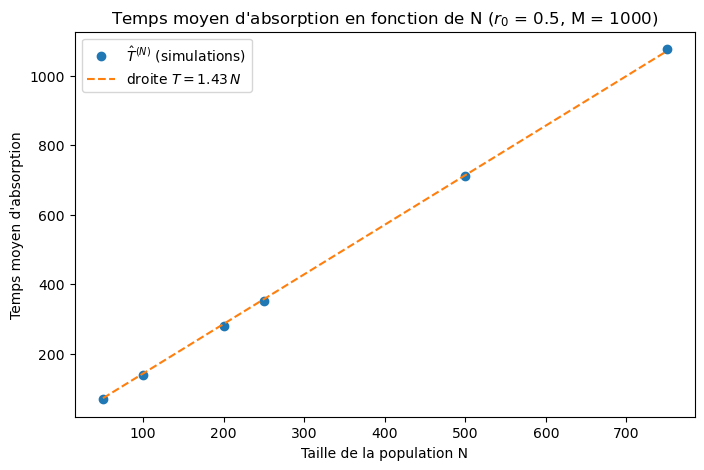

In [29]:
# pente de la droite T = a*N passant par l'origine (moindres carrés)
a = np.sum(liste_N * T_moy) / np.sum(liste_N**2)

plt.figure(figsize=(8, 5))
plt.plot(liste_N, T_moy, "o", label="$\\hat T^{(N)}$ (simulations)")
plt.plot(liste_N, a * liste_N, "--", label=f"droite $T = {a:.2f}\\,N$")
plt.xlabel("Taille de la population N")
plt.ylabel("Temps moyen d'absorption")
plt.title(f"Temps moyen d'absorption en fonction de N ($r_0$ = {r0}, M = {M})")
plt.legend()
plt.show()

 Les points obtenus par simulation sont presque parfaitement alignés sur une droite passant par l'origine, de pente environ 1,43. Le temps moyen d'absorption augmente donc linéairement avec la taille de la population, ce qui confirme la conjecture :

E[T] ≈ 1,4 × N (pour r₀ = 1/2).

Plus la population est grande, plus la dérive génétique est lente, et plus il faut de générations pour qu'un des deux allèles disparaisse.

In [30]:
# question 4

# fonction h
def h(r):
    return 2 * (-r * np.log(r) - (1 - r) * np.log(1 - r))

In [31]:
# calcul du temps moyen en fonction de r0
rng = np.random.default_rng(0)
N = 100
M = 1000
liste_r0 = np.arange(0.05, 1.0, 0.05)      # 0.05, 0.10, ..., 0.95

T_moy_r = []
for r0 in liste_r0:
    n0 = round(N * r0)
    temps = [temps_absorption(N, n0, rng)[0] for _ in range(M)]
    T_moy_r.append(np.mean(temps))
T_moy_r = np.array(T_moy_r)

for r0, T in zip(liste_r0, T_moy_r):
    print(f"r0 = {r0:.2f}   T moyen / N = {T/N:.2f}   h(r0) = {h(r0):.2f}")

r0 = 0.05   T moyen / N = 0.41   h(r0) = 0.40
r0 = 0.10   T moyen / N = 0.60   h(r0) = 0.65
r0 = 0.15   T moyen / N = 0.78   h(r0) = 0.85
r0 = 0.20   T moyen / N = 1.01   h(r0) = 1.00
r0 = 0.25   T moyen / N = 1.14   h(r0) = 1.12
r0 = 0.30   T moyen / N = 1.28   h(r0) = 1.22
r0 = 0.35   T moyen / N = 1.30   h(r0) = 1.29
r0 = 0.40   T moyen / N = 1.30   h(r0) = 1.35
r0 = 0.45   T moyen / N = 1.34   h(r0) = 1.38
r0 = 0.50   T moyen / N = 1.37   h(r0) = 1.39
r0 = 0.55   T moyen / N = 1.34   h(r0) = 1.38
r0 = 0.60   T moyen / N = 1.37   h(r0) = 1.35
r0 = 0.65   T moyen / N = 1.25   h(r0) = 1.29
r0 = 0.70   T moyen / N = 1.19   h(r0) = 1.22
r0 = 0.75   T moyen / N = 1.08   h(r0) = 1.12
r0 = 0.80   T moyen / N = 0.97   h(r0) = 1.00
r0 = 0.85   T moyen / N = 0.79   h(r0) = 0.85
r0 = 0.90   T moyen / N = 0.65   h(r0) = 0.65
r0 = 0.95   T moyen / N = 0.40   h(r0) = 0.40


Interprétation. Les valeurs simulées de T̂/N sont très proches de h(r₀). On conjecture donc :

E[T] ≈ N × h(r₀).

Le temps moyen d’absorption est maximal pour r₀ = 1/2 et diminue quand r₀ se rapproche de 0 ou de 1 : plus on part près d’une des deux issues, plus l’absorption est rapide. Il est aussi symétrique, car h(r₀) = h(1 − r₀) : les allèles A et a jouent des rôles identiques. Pour r₀ = 1/2, on retrouve E[T] ≈ 1,39 × N, ce qui est cohérent avec la question 3.

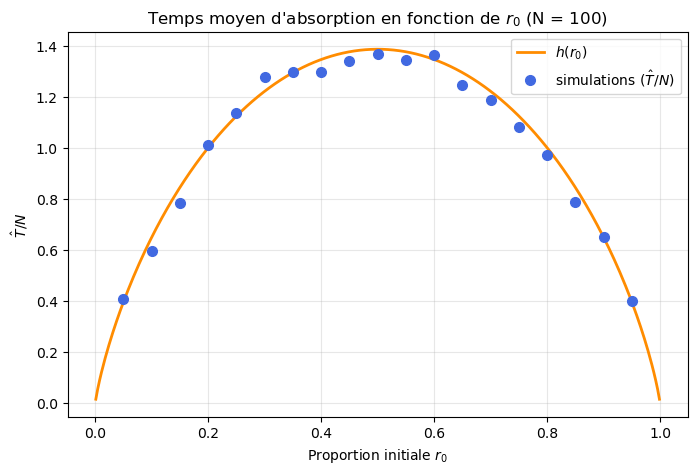

In [ ]:
figure en couleur
r = np.linspace(0.001, 0.999, 300)

plt.figure(figsize=(8, 5))
plt.plot(r, h(r), color="darkorange", lw=2, label="$h(r_0)$")
plt.plot(liste_r0, T_moy_r / N, "o", color="royalblue", markersize=7,
         label="simulations ($\\hat T / N$)")
plt.xlabel("Proportion initiale $r_0$")
plt.ylabel("$\\hat T / N$")
plt.title(f"Temps moyen d'absorption en fonction de $r_0$ (N = {N})")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Les points simulés (en bleu) suivent de près la courbe de h (en orange), qui a la forme d’une cloche symétrique avec un maximum en r₀ = 1/2. Les petits écarts observés, par exemple autour de r₀ = 0,1 ou 0,4, sont dus au caractère aléatoire des simulations. La figure confirme donc la conjecture E[T] ≈ N × h(r₀).

In [33]:
# Question 5– calcul de la probabilité de fixation
rng = np.random.default_rng(0)
liste_r0 = np.arange(0.05, 1.0, 0.05)
liste_N_q5 = [50, 100, 200]
M = 1000

p_fix = {}
for N in liste_N_q5:
    p = []
    for r0 in liste_r0:
        n0 = round(N * r0)
        fixes = [temps_absorption(N, n0, rng)[1] == "A" for _ in range(M)]
        p.append(np.mean(fixes))
    p_fix[N] = np.array(p)

for i, r0 in enumerate(liste_r0):
    print(f"r0 = {r0:.2f}   " + "   ".join(f"N={N}: {p_fix[N][i]:.2f}" for N in liste_N_q5))

r0 = 0.05   N=50: 0.05   N=100: 0.04   N=200: 0.04
r0 = 0.10   N=50: 0.08   N=100: 0.09   N=200: 0.09
r0 = 0.15   N=50: 0.15   N=100: 0.15   N=200: 0.16
r0 = 0.20   N=50: 0.19   N=100: 0.19   N=200: 0.20
r0 = 0.25   N=50: 0.23   N=100: 0.22   N=200: 0.23
r0 = 0.30   N=50: 0.28   N=100: 0.29   N=200: 0.29
r0 = 0.35   N=50: 0.36   N=100: 0.35   N=200: 0.36
r0 = 0.40   N=50: 0.40   N=100: 0.43   N=200: 0.41
r0 = 0.45   N=50: 0.45   N=100: 0.45   N=200: 0.45
r0 = 0.50   N=50: 0.47   N=100: 0.53   N=200: 0.49
r0 = 0.55   N=50: 0.55   N=100: 0.53   N=200: 0.52
r0 = 0.60   N=50: 0.61   N=100: 0.62   N=200: 0.59
r0 = 0.65   N=50: 0.64   N=100: 0.63   N=200: 0.65
r0 = 0.70   N=50: 0.71   N=100: 0.71   N=200: 0.69
r0 = 0.75   N=50: 0.75   N=100: 0.73   N=200: 0.76
r0 = 0.80   N=50: 0.79   N=100: 0.79   N=200: 0.80
r0 = 0.85   N=50: 0.86   N=100: 0.86   N=200: 0.84
r0 = 0.90   N=50: 0.89   N=100: 0.90   N=200: 0.90
r0 = 0.95   N=50: 0.95   N=100: 0.95   N=200: 0.94


Pour chaque valeur de r₀, la probabilité de fixation estimée est très proche de r₀ : par exemple environ 0,20 pour r₀ = 0,20, et environ 0,90 pour r₀ = 0,90. Les résultats sont pratiquement les mêmes pour N = 50, 100 et 200. On conjecture donc que la probabilité de fixation ne dépend pas de la taille de la population :

P(n_T = N) = r₀ et P(n_T = 0) = 1 − r₀.

Autrement dit, un allèle a d’autant plus de chances de se fixer qu’il est fréquent au départ.

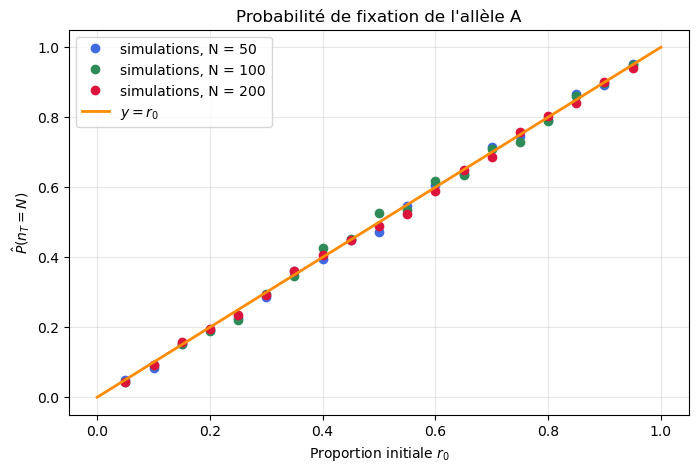

In [34]:
# figure
couleurs = {50: "royalblue", 100: "seagreen", 200: "crimson"}

plt.figure(figsize=(8, 5))
for N in liste_N_q5:
    plt.plot(liste_r0, p_fix[N], "o", color=couleurs[N], label=f"simulations, N = {N}")
plt.plot([0, 1], [0, 1], color="darkorange", lw=2, label="$y = r_0$")
plt.xlabel("Proportion initiale $r_0$")
plt.ylabel("$\\hat P(n_T = N)$")
plt.title("Probabilité de fixation de l'allèle A")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

 Les points simulés pour N = 50 (en bleu), N = 100 (en vert) et N = 200 (en rouge) se superposent tous le long de la droite y = r₀ (en orange). Les petits écarts, par exemple autour de r₀ = 0,5, sont dus au hasard des simulations. La figure confirme donc que la probabilité de fixation de A est égale à r₀, quelle que soit la taille de la population.